# Text Summarization: Workflow Overview

| Item | Description |
|---|---|
| Goal | Guide a reader through the T1 section: how each congressional hearing transcript became one summary written by a local language model, how the model and the prompts were chosen, how the summaries were checked against C-SPAN's abstracts, and how one hearing can be followed through every step. |
| Covers | The seven notebooks of T1.1 to T1.4, their inputs and outputs, where the data live, and how to obtain every input again. |
| Output | None. This notebook runs no step and writes no file. |
| Run | Not applicable. The GPU steps ran in August 2026 and are not rerun; the validation similarities and figure were recomputed on a GPU node on 2026-10-31. Each notebook states its own run in its header. |

A hearing in the sample is a median 36,505 words, about 49,000 tokens, and the longest is 376,848 words. No small model reads that in one pass. So each transcript is cut into chunks of whole speaking turns, and each chunk is summarized. The segment summaries are then condensed until one call can write the summary of the whole hearing. The model is Qwen3.5-4B, run locally on one GPU per task.

## 1. The process at a glance

The chart below is the T1 flowchart from `R - Results/figures/T - Three Step Text Analysis Pipeline/T1 - Text Summarization`.

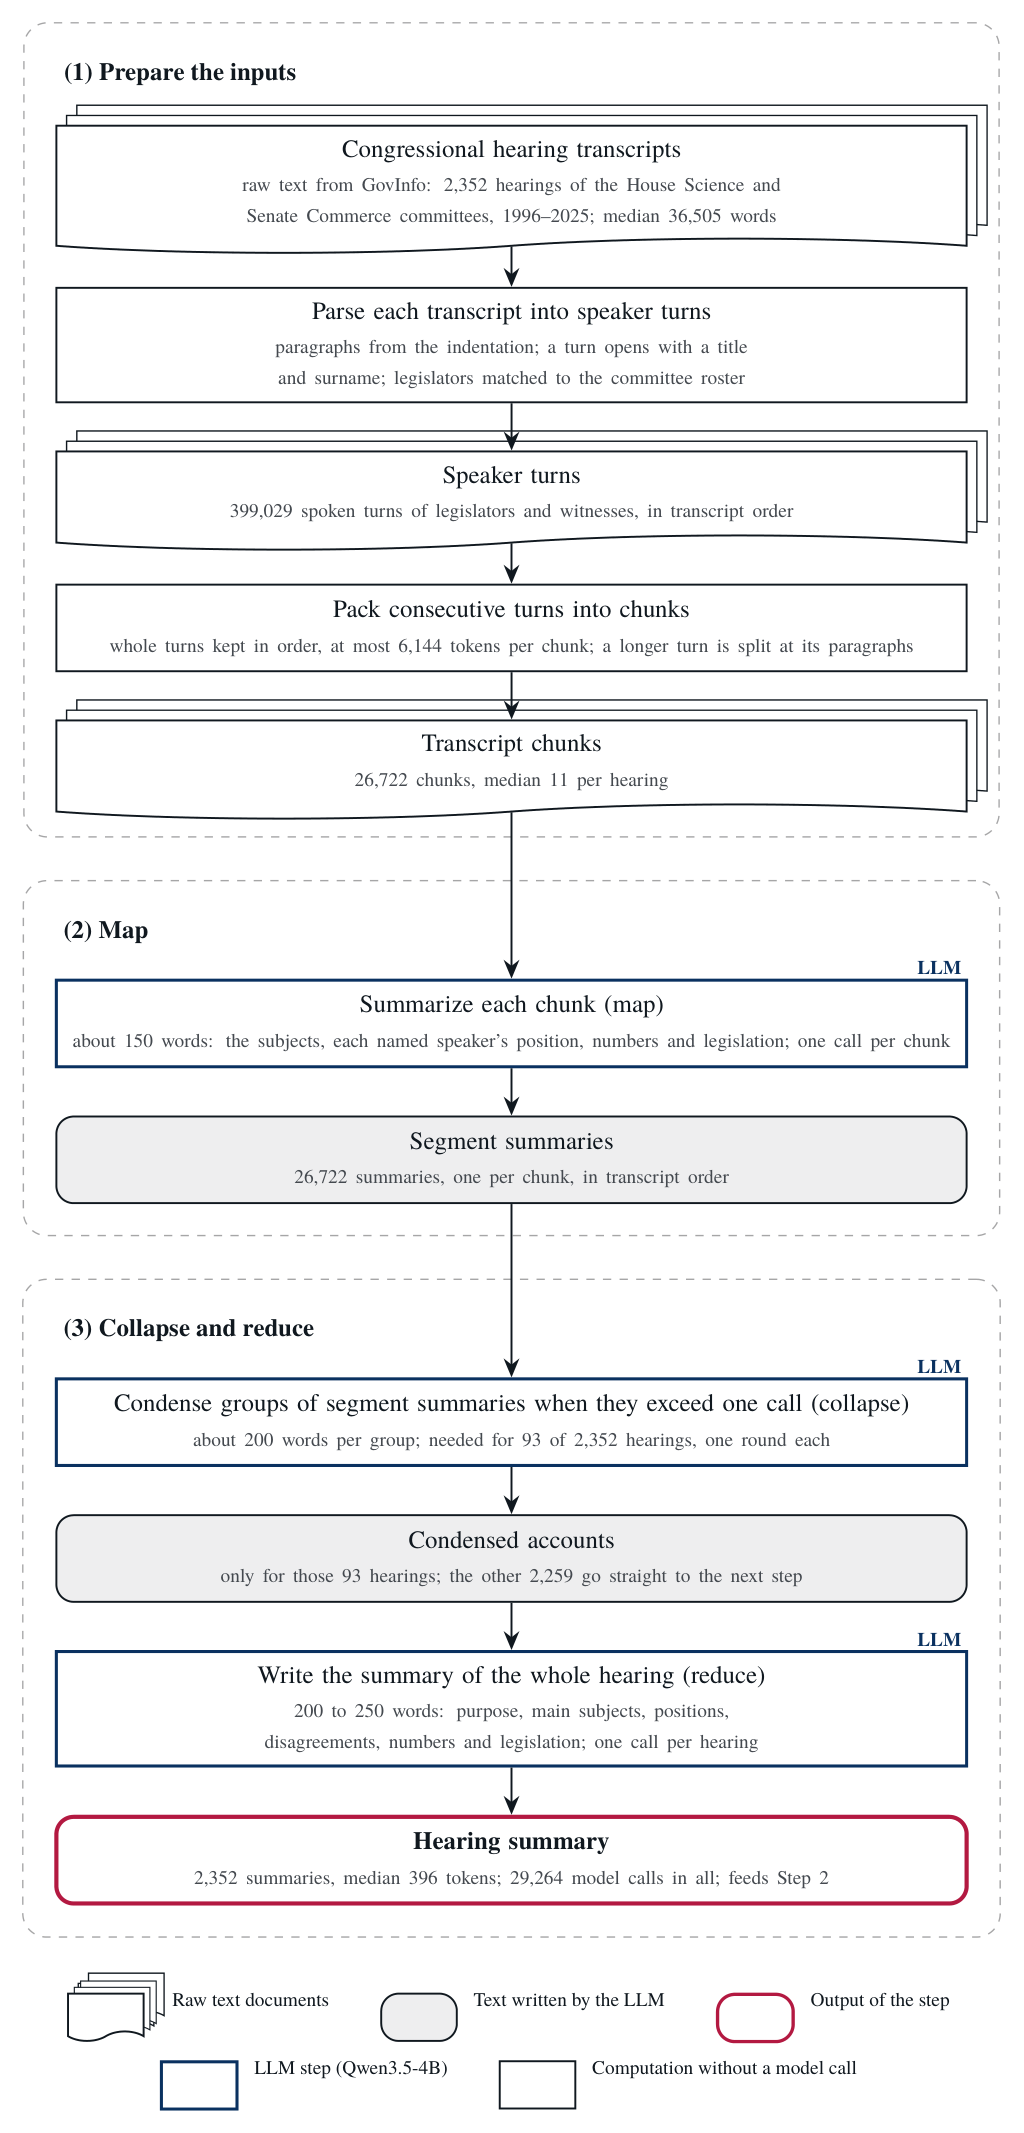

In [1]:
from pathlib import Path
from IPython.display import Image, display

PROJECT_FOLDER = Path.cwd().resolve().parents[1]  # <pipeline>/<section>/ sits two levels below the clone
display(Image(filename=PROJECT_FOLDER / "R - Results/figures/T - Three Step Text Analysis Pipeline/T1 - Text Summarization/fig_text_summarization_flowchart.png", width=620))

Three stages, and three prompts. **Map**: each chunk of whole speaking turns, at most 6,144 tokens, becomes a summary of about 150 words that names who said what. **Collapse**: when the segment summaries of a hearing do not fit in one call, they are grouped within the budget and condensed. 93 of the 2,352 hearings needed it. **Reduce**: one call writes the summary of the whole hearing in 200 to 250 words. The cap of 512 tokens lets the encoder used later read all of it. The production run made 29,264 model calls in 113 GPU hours.

The section has four parts. [T1.1.1 - Draft - Map-Reduce on Two Hearings](T1.1%20-%20Process%20Prototyping%20and%20Evaluation/T1.1.1%20-%20Draft%20-%20Map-Reduce%20on%20Two%20Hearings.ipynb) and [T1.1.2 - Compare - Four Models on Five Hearings](T1.1%20-%20Process%20Prototyping%20and%20Evaluation/T1.1.2%20-%20Compare%20-%20Four%20Models%20on%20Five%20Hearings.ipynb) are the prototyping: the prompts, a draft on two hearings, and the comparison of four models that settled on Qwen3.5-4B. [T1.2.1 - Production - Summarize the Sample in Shards](T1.2%20-%20Process%20Entire%20Sample%20Congressional%20Hearings/T1.2.1%20-%20Production%20-%20Summarize%20the%20Sample%20in%20Shards.ipynb) and [T1.2.2 - Production - Assemble the Summaries](T1.2%20-%20Process%20Entire%20Sample%20Congressional%20Hearings/T1.2.2%20-%20Production%20-%20Assemble%20the%20Summaries.ipynb) are the production run over the sample and its assembly into one table. [T1.3.1 - Validation - Match C-SPAN Programs to Hearings](T1.3%20-%20Validation%20of%20Summaries/T1.3.1%20-%20Validation%20-%20Match%20C-SPAN%20Programs%20to%20Hearings.ipynb) and [T1.3.2 - Validation - Compare Summaries with C-SPAN Abstracts](T1.3%20-%20Validation%20of%20Summaries/T1.3.2%20-%20Validation%20-%20Compare%20Summaries%20with%20C-SPAN%20Abstracts.ipynb) are the validation against C-SPAN's abstracts. [T1.4.1 - Example - The Facebook Hearing Step by Step](T1.4%20-%20Running%20Example%20%5BFacebook-Cambridge%20Analytica%20Scandal%20Hearing%5D/T1.4.1%20-%20Example%20-%20The%20Facebook%20Hearing%20Step%20by%20Step.ipynb) follows the Facebook hearing of April 10, 2018 through all of it.

## 2. Datasets

| Dataset | Produced by | Rows | Final output, in the subfolder's `Processed` folder |
|---|---|---|---|
| Science committee sample | D4 | 2,352 hearings | input to T1, `hearings_sst.parquet` |
| Model comparison | T1.1.2 | 20 hearing-model pairs | `Interim/compare/comparison.parquet` in T1.1, with the call logs of each model beside it |
| Hearing summaries | T1.2.1 and T1.2.2 | 2,352 summaries | `hearing_summaries.parquet` in T1.2: metadata, run measurements, and `summary` |
| C-SPAN matches | T1.3.1 | 3,812 matches, 351 with a summary | `cspan_matches.parquet` in T1.3 |
| Summary-abstract similarities | T1.3.2 | 1.34 million pairs | `Interim/summary_abstract_pairs.parquet` in T1.3, with the embeddings beside it |

## 3. The notebooks, in running order

Each notebook does one step and reads only files the notebooks above it wrote. Links are relative to this folder.

| Notebook | What it does | Reads | Writes | Runs again? |
|---|---|---|---|---|
| [T1.1.1 - Draft - Map-Reduce on Two Hearings](T1.1%20-%20Process%20Prototyping%20and%20Evaluation/T1.1.1%20-%20Draft%20-%20Map-Reduce%20on%20Two%20Hearings.ipynb) | Shows the three prompts and summarizes two hearings as a draft | the sample; the model | nothing | No, GPU |
| [T1.1.2 - Compare - Four Models on Five Hearings](T1.1%20-%20Process%20Prototyping%20and%20Evaluation/T1.1.2%20-%20Compare%20-%20Four%20Models%20on%20Five%20Hearings.ipynb) | Runs five hearings through four models and records what each costs | the sample; four models | the comparison table and call logs | No, GPU |
| [T1.2.1 - Production - Summarize the Sample in Shards](T1.2%20-%20Process%20Entire%20Sample%20Congressional%20Hearings/T1.2.1%20-%20Production%20-%20Summarize%20the%20Sample%20in%20Shards.ipynb) | Summarizes the 2,352 hearings in ten shards, resumable | the sample; the model | a call log per hearing, a table per shard | No, 113 GPU hours |
| [T1.2.2 - Production - Assemble the Summaries](T1.2%20-%20Process%20Entire%20Sample%20Congressional%20Hearings/T1.2.2%20-%20Production%20-%20Assemble%20the%20Summaries.ipynb) | Joins the shards and the hearing metadata into one table | the shard tables; the sample | `hearing_summaries.parquet` | Yes, seconds |
| [T1.3.1 - Validation - Match C-SPAN Programs to Hearings](T1.3%20-%20Validation%20of%20Summaries/T1.3.1%20-%20Validation%20-%20Match%20C-SPAN%20Programs%20to%20Hearings.ipynb) | Matches C-SPAN programs to hearings on date, chamber, title, and witnesses | all hearings; all programs | `cspan_matches.parquet` | Yes, seconds |
| [T1.3.2 - Validation - Compare Summaries with C-SPAN Abstracts](T1.3%20-%20Validation%20of%20Summaries/T1.3.2%20-%20Validation%20-%20Compare%20Summaries%20with%20C-SPAN%20Abstracts.ipynb) | Embeds summaries and abstracts, compares three sets of pairs, draws the figure | the matches; the summaries; the encoder | embeddings, the pair table, the figure | Yes, a short GPU job |
| [T1.4.1 - Example - The Facebook Hearing Step by Step](T1.4%20-%20Running%20Example%20%5BFacebook-Cambridge%20Analytica%20Scandal%20Hearing%5D/T1.4.1%20-%20Example%20-%20The%20Facebook%20Hearing%20Step%20by%20Step.ipynb) | Rebuilds the Facebook hearing's chunks and verifies all 59 logged calls | the transcript, the turns, the call log | the readable copies beside it | Yes, a minute |

The job scripts of the two GPU runs are in `J - Jobs`: `run_T1.2.1_summarize_sst.sbatch`, the ten-task array of August, and `run_T1.3.2_cspan_similarity.sbatch`.

## 4. Where the data live

The notebooks read and write under the scratch root `/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis`, in the layout [S5](../../S--Style/S5--Saving_Files.md) defines: `T1 - Text Summarization/<subfolder>/Interim` and `Processed`. Model weights sit in `cache/huggingface` under the same root. The readable copies of the running example are the one exception: they live beside T1.4.1 in the repository, because the proposal links to them.

## 5. How to obtain the inputs

**The sample.** `hearings_sst.parquet` is built by D; see the D overview for how the transcripts are collected.

**The models.** Qwen3.5-4B and the encoder bge-large-en-v1.5 download from the Hugging Face Hub without a token; the first use writes them to `cache/huggingface`. The two Llama checkpoints of the comparison are gated. Accept their licences on the Hub and put a read token in `.env` in this folder, following `.env.example`.

**The hardware.** Each GPU step ran on one NVIDIA A40 in bfloat16; any card with 16 GB and compute capability 8.0 or above serves. The production run needs about 113 GPU hours and is not meant to be repeated; its outputs are on the scratch root.

## 6. How to read a notebook in this section

Every notebook opens with the same table and a Run row that says when it ran and why it is or is not rerun. The GPU notebooks keep the cell outputs of their August run as evidence. T1.2.1 shows the executed copy of shard 0 and ends with a cell that reads the logs of all ten shards. T1.3.2 is the one GPU notebook rerun on 2026-10-31, to store the similarities the first run did not keep. The CPU notebooks were rebuilt into scratch copies on 2026-10-31 and found identical to the stored tables. The helper code of the earlier version, the chunker and the three prompts, is written out inside each notebook that uses it.